## Data Engineering Platforms
#### Desc:  Connecting to MySQL from Jupyter Notebook

Python packages:                       
`pip install sqlalchemy`                   
`pip install mysql-connector-python`

https://www.sqlalchemy.org/

SQLAlchemy considers the database to be a relational algebra engine, not just a collection of tables. Rows can be selected from not only tables but also joins and other select statements; any of these units can be composed into a larger structure. SQLAlchemy's expression language builds on this concept from its core.

In [18]:
!pip install sqlalchemy mysql-connector-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 41.6 MB/s  0:00:00 41.7 MB/s eta 0:00:01


In [19]:
import numpy as np
import pandas as pd
import sqlalchemy as db
from sqlalchemy import  MetaData, Table, select, func
from sqlalchemy.orm import Session

from IPython.display import Image, display
import matplotlib.pyplot as plt

In [20]:
print("Numpy :", np.__version__)
print("Pandas :", pd.__version__)
print("SQLAlchemy :", db.__version__)

Numpy : 2.2.6
Pandas : 2.3.3
SQLAlchemy : 2.0.51


### Connect to DB

In [21]:
# Create SQLAlchemy engine
#engine = db.create_engine(f"mysql+mysqlconnector://{user}:{password}@{host}/{database}")
engine = db.create_engine(f"mysql+mysqlconnector://root:@localhost/classicmodels")

# Connect to the database
with engine.connect() as connection:
    print("Database connection successful.")

Database connection successful.


In [22]:
#establish the connection
connection = engine.connect()

In [23]:
# Create a MetaData instance
metadata = db.MetaData()

# Reflect the database schema
metadata.reflect(bind=engine)

### Get DB Information

In [24]:
# Get table information
inspector = db.inspect(engine)
inspector.get_table_names()

['customers',
 'employees',
 'offices',
 'orderdetails',
 'orders',
 'payments',
 'productlines',
 'products']

In [25]:
#list all columns from table
inspector.get_columns('customers')

[{'name': 'customerNumber',
  'type': INTEGER(),
  'default': None,
  'comment': None,
  'nullable': False,
  'autoincrement': False},
 {'name': 'customerName',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'contactLastName',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'contactFirstName',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'phone',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'addressLine1',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'addressLine2',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': True},
 {'name': 'city',
  'type': VARCHAR(length=50),
  'default': None,
  'comment': None,
  'nullable': False},
 {'name': 'state',
  'type': VARCHAR(length=50),
  'default': 

In [26]:
# Access the 'Customers' table
customers = db.Table('Customers', metadata, autoload_with=engine)

In [27]:
# Print the column names
customers.columns.keys()

['customerNumber',
 'customerName',
 'contactLastName',
 'contactFirstName',
 'phone',
 'addressLine1',
 'addressLine2',
 'city',
 'state',
 'postalCode',
 'country',
 'salesRepEmployeeNumber',
 'creditLimit']

In [28]:
# Print the column names
customers.columns.values()

[Column('customerNumber', INTEGER(), table=<Customers>, primary_key=True, nullable=False),
 Column('customerName', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('contactLastName', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('contactFirstName', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('phone', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('addressLine1', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('addressLine2', VARCHAR(length=50), table=<Customers>),
 Column('city', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('state', VARCHAR(length=50), table=<Customers>),
 Column('postalCode', VARCHAR(length=15), table=<Customers>),
 Column('country', VARCHAR(length=50), table=<Customers>, nullable=False),
 Column('salesRepEmployeeNumber', INTEGER(), ForeignKey('employees.employeeNumber'), table=<Customers>),
 Column('creditLimit', DECIMAL(precision=10, scale=2), table=<Customers>)]

### Raw SQL

In [29]:
def executeSQLQuery(engine, sql_query):
    with engine.connect() as connection:
        # Execute the query with parameter binding
        result_set = connection.execute(db.text(sql_query))
        
        results = result_set.fetchall()
        columns=list(result_set.keys())

        # Check if there are any results
        if results:
            # Create DataFrame using the fetched data and column names
            #print(columns)
            results_df = pd.DataFrame(results, columns=columns)
        else:
            # Return an empty DataFrame with the correct columns
            results_df = pd.DataFrame(columns=columns)
        
        return results_df

In [30]:
## SQL
df = executeSQLQuery(engine, ''' SELECT * FROM Customers''')
df.head()

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,103,Atelier graphique,Schmitt,Carine,40.32.2555,"54, rue Royale",None,Nantes,None,44000,France,1370.0,21000.00
1,112,Signal Gift Stores,King,Jean,7025551838,8489 Strong St.,None,Las Vegas,NV,83030,USA,1166.0,71800.00
2,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611.0,117300.00
3,119,La Rochelle Gifts,Labrune,Janine,40.67.8555,"67, rue des Cinquante Otages",None,Nantes,None,44000,France,1370.0,118200.00
4,121,Baane Mini Imports,Bergulfsen,Jonas,07-98 9555,Erling Skakkes gate 78,None,Stavern,None,4110,Norway,1504.0,81700.00


In [31]:
#Number of customers by country
df = executeSQLQuery(engine, "SELECT country,count(*) FROM customers GROUP BY country")
df.head()

,country,count(*)
0,France,12
1,USA,36
2,Australia,5
3,Norway,3
4,Poland,1


<Axes: xlabel='Order Status'>

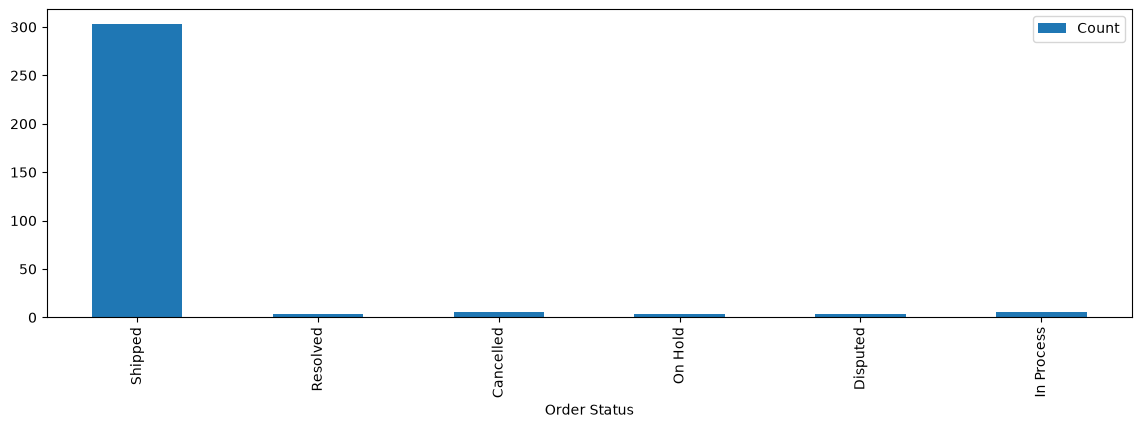

In [32]:
#Number of orders by status
df = executeSQLQuery(engine, "SELECT status,count(*) FROM orders GROUP BY status")
df.head()
df.columns = ["Order Status", "Count"]
df.plot('Order Status',figsize=(14,4), kind='bar')

In [33]:
#Number of orders by date
df1 = executeSQLQuery(engine, "SELECT orderdate,count(*) as Ordered FROM orders GROUP BY orderdate")
df2 = executeSQLQuery(engine, "SELECT shippeddate,count(*) as Shipped FROM orders GROUP BY shippeddate")

# Rename columns for clarity
df1.rename(columns={'orderdate': 'date'}, inplace=True)
df2.rename(columns={'shippeddate': 'date'}, inplace=True)

# Merge DataFrames on the date column
df = pd.merge(df1, df2, on='date', how='outer')

# Display the merged DataFrame
df.head(10)

,date,Ordered,Shipped
0,2014-01-02,1.0,NaN
1,2014-01-04,NaN,1.0
2,2014-01-09,1.0,NaN
3,2014-01-12,1.0,1.0
4,2014-01-15,1.0,NaN
5,2014-01-16,1.0,NaN
6,2014-01-18,NaN,2.0
7,2014-01-20,NaN,1.0
8,2014-01-22,1.0,NaN
9,2014-01-26,1.0,NaN


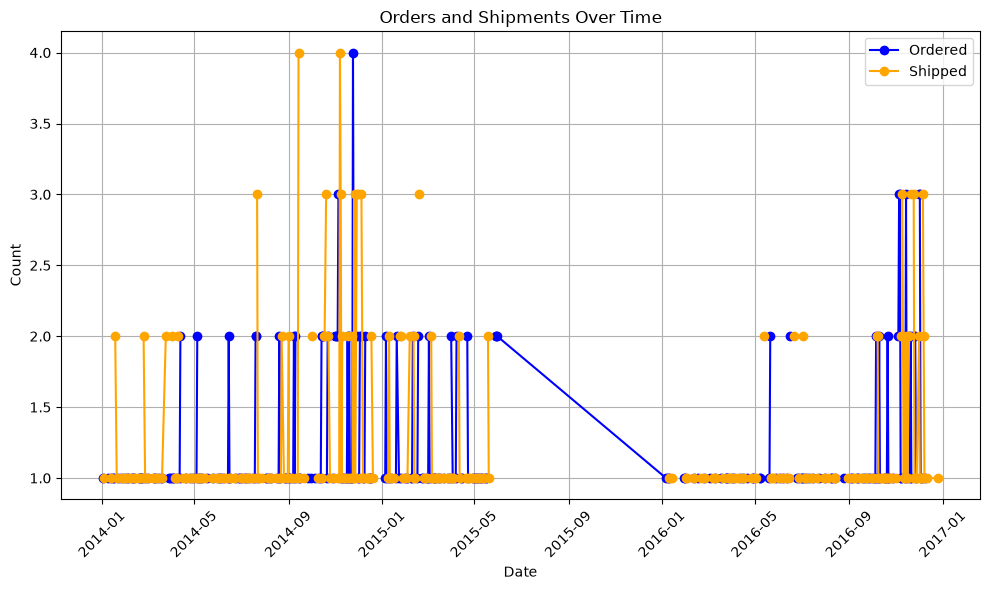

In [34]:
# Set the date as the index
df.set_index('date', inplace=True)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Ordered'], marker='o', label='Ordered', color='blue')
plt.plot(df.index, df['Shipped'], marker='o', label='Shipped', color='orange')

plt.title('Orders and Shipments Over Time')
plt.xlabel('Date')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### ORM 

In [35]:
## SQLAlchemy
session = Session(engine)
result_set = session.execute(select(customers))
df = pd.DataFrame(result_set.fetchall(), columns=result_set.keys())
df.head()

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,103,Atelier graphique,Schmitt,Carine,40.32.2555,"54, rue Royale",None,Nantes,None,44000,France,1370.0,21000.00
1,112,Signal Gift Stores,King,Jean,7025551838,8489 Strong St.,None,Las Vegas,NV,83030,USA,1166.0,71800.00
2,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611.0,117300.00
3,119,La Rochelle Gifts,Labrune,Janine,40.67.8555,"67, rue des Cinquante Otages",None,Nantes,None,44000,France,1370.0,118200.00
4,121,Baane Mini Imports,Bergulfsen,Jonas,07-98 9555,Erling Skakkes gate 78,None,Stavern,None,4110,Norway,1504.0,81700.00


In [36]:
#Customers in USA and Spain
session = Session(engine)
stmt = select(customers).where(customers.c.country.in_(["USA", "Spain"]))
result_set = session.execute(stmt)
df = pd.DataFrame(result_set.fetchall(), columns=result_set.keys())
df.head()

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,112,Signal Gift Stores,King,Jean,7025551838,8489 Strong St.,None,Las Vegas,NV,83030,USA,1166.0,71800.00
1,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,None,San Rafael,CA,97562,USA,1165.0,210500.00
2,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,None,San Francisco,CA,94217,USA,1165.0,64600.00
3,131,Land of Toys Inc.,Lee,Kwai,2125557818,897 Long Airport Avenue,None,NYC,NY,10022,USA,1323.0,114900.00
4,141,Euro+ Shopping Channel,Freyre,Diego,(91) 555 94 44,"C/ Moralzarzal, 86",None,Madrid,None,28034,Spain,1370.0,227600.00


In [37]:
# Define the 'Orders' table
orders = Table('Orders', metadata, autoload_with=engine)
result_set = session.execute(select(orders))
df = pd.DataFrame(result_set.fetchall(), columns=result_set.keys())
df.head()

,orderNumber,orderDate,requiredDate,shippedDate,status,comments,customerNumber
0,10100,2016-01-06,2016-01-13,2016-01-10,Shipped,None,363
1,10101,2016-01-09,2016-01-18,2016-01-11,Shipped,Check on availability.,128
2,10102,2016-01-10,2016-01-18,2016-01-14,Shipped,None,181
3,10103,2016-01-29,2016-02-07,2016-02-02,Shipped,None,121
4,10104,2016-01-31,2016-02-09,2016-02-01,Shipped,None,141


### Partial Fetching

For large tables, fetching all rows could lead to timeout or memory issues. Fetch few records at a time. 

Limit and Offset: The query uses limit(10) to fetch only 10 rows and offset(0) to start from the first row. You can change these values to control the pagination.

In [38]:
# Create a session
with Session(engine) as session:
    # Define the query
    stmt = select(orders).limit(10).offset(0)  # Fetch the first 10 rows

    # Execute the query
    result_set = session.execute(stmt)

    # Convert the result to a DataFrame
    df = pd.DataFrame(result_set.fetchall(), columns=result_set.keys())

df.head()

,orderNumber,orderDate,requiredDate,shippedDate,status,comments,customerNumber
0,10100,2016-01-06,2016-01-13,2016-01-10,Shipped,None,363
1,10101,2016-01-09,2016-01-18,2016-01-11,Shipped,Check on availability.,128
2,10102,2016-01-10,2016-01-18,2016-01-14,Shipped,None,181
3,10103,2016-01-29,2016-02-07,2016-02-02,Shipped,None,121
4,10104,2016-01-31,2016-02-09,2016-02-01,Shipped,None,141


In [39]:
#Next Page
offset_value = 10  # Change this to fetch the next set
stmt = select(orders).limit(10).offset(offset_value)
result_set = session.execute(stmt)
df = pd.DataFrame(result_set.fetchall(), columns=result_set.keys())
df.head()

,orderNumber,orderDate,requiredDate,shippedDate,status,comments,customerNumber
0,10110,2016-03-18,2016-03-24,2016-03-20,Shipped,None,187
1,10111,2016-03-25,2016-03-31,2016-03-30,Shipped,None,129
2,10112,2016-03-24,2016-04-03,2016-03-29,Shipped,Customer requested that ad materials (such as ...,144
3,10113,2016-03-26,2016-04-02,2016-03-27,Shipped,None,124
4,10114,2016-04-01,2016-04-07,2016-04-02,Shipped,None,172


### Plot ER Model

Download and install https://graphviz.gitlab.io/download/

`pip install pydot pydotplus graphviz sqlalchemy_schemadisplay`

In [40]:
!pip install pydot pydotplus graphviz sqlalchemy_schemadisplay

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pydotplus: filename=pydotplus-2.0.2-py3-none-any.whl size=24636 sha256=396907472fbb13c66ddbdbf6f09b5d0ccbeaa5a585fc622293c80df9142ba4ff
  Stored in directory: /Users/apujari/Library/Caches/pip/wheels/6a/63/32/4f9ae76d466cda6468f0f08c24a8b4b5344487d8b2f8e1e0d1
Successfully built pydotplus
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [sqlalchemy_schemadisplay]


In [41]:
from sqlalchemy_schemadisplay import create_schema_graph

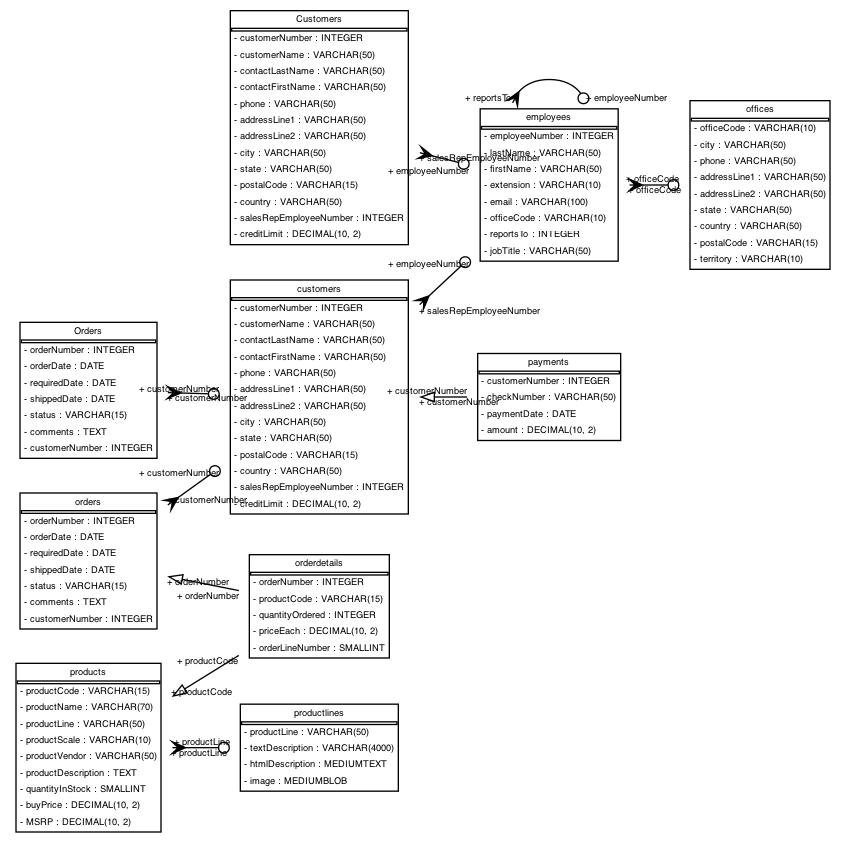

In [42]:
# Create the pydot graph object by autoloading all tables via a bound metadata object
graph = create_schema_graph(
    engine=engine,
    metadata=metadata,
    show_datatypes=True,  # Show data types
    show_indexes=True,     # Show indexes
    rankdir='LR',         # Layout from left to right
    concentrate=False      # Avoid joining relation lines
)

# Set node defaults
graph.set_node_defaults(shape='box', style='filled', fillcolor='#E0E0E0', fontcolor='#333333')

# Set edge defaults
graph.set_edge_defaults(color='#007ACC')  # Blue color for edges

# Save the graph as a PNG file
graph.write_png('dbschema.png')  # Optionally save the graph to a file
plt = Image(graph.create_png())
display(plt)